# Imports

In [4]:
import zipfile

from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import geopandas as gpd
import jax, jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

plt.style.use('../hugo/pgf.mplstyle')
plt.rcParams['font.family'] = 'serif'
jax.config.update("jax_enable_x64", True)

# Unzip Data

In [5]:
# unzip ../data/trip_count/trip_count_matrix_county_by_age_activity_final_2024.zip to csv file
with zipfile.ZipFile("../data/trip_count/trip_count_matrix_county_by_age_activity_final_2024.zip", 'r') as zip_ref:
    zip_ref.extractall("../data/trip_count/")

In [6]:
with zipfile.ZipFile("../data/vg250/DE_VG250.zip", 'r') as zip_ref:
    zip_ref.extractall("../data/vg250/")

# Load Data

In [7]:
# load the data
df_trips = pl.read_csv("../data/trip_count/trip_count_matrix_county_by_age_activity_final_2024.csv")
df_trips = df_trips.group_by(["start_county", "end_county"]).agg(pl.sum("trip_cnt").alias("trip_cnt")) # puts the same trips together
df_trips.head() # Trips in between counties, counties marked by numbers

start_county,end_county,trip_cnt
i64,i64,i64
7336,8221,47
6439,5970,312
7316,7333,217
8116,8212,1412
5370,5116,29513


In [8]:
df_population = pl.read_csv("../data/population/12411-0016_de.csv", separator=";", skip_rows=5)
df_population = df_population.select([pl.col("_duplicated_0").alias("county"),
                                     pl.col("_duplicated_1").alias("county_name"),
                                     pl.col("Insgesamt").alias("population")])
df_population = df_population.drop_nulls()
df_population = df_population.filter(pl.col("population") != "-")
df_population = df_population.with_columns(pl.col("population").cast(pl.Int64))
df_population = df_population.sort("county") # sort the rows by county identifier
df_population.head() # population size of each county. has the id and name of each county

county,county_name,population
i64,str,i64
1001,"""Flensburg, kreisfreie Stadt""",95568
1002,"""Kiel, kreisfreie Stadt""",251842
1003,"""Lübeck, kreisfreie Stadt""",217061
1004,"""Neumünster, kreisfreie Stadt""",80145
1051,"""Dithmarschen, Landkreis""",133405


In [ ]:
# sorted list of counties
start_counties = sorted(df_trips["start_county"].unique())
end_counties = sorted(df_trips["end_county"].unique())
assert start_counties == end_counties, "Start and end counties do not match" 
# create a dictionary mapping each county id -> index (int)
county_to_index = {county: i for i, county in enumerate(start_counties)}

# Building the movement matrix W
W = np.zeros((len(start_counties), len(end_counties))) # one row and column for each county
for row in df_trips.iter_rows():
    start_county, end_county, trip_cnt = row # read one row of df_trips
    if start_county == end_county:
        continue

    # find the matrix positions (translate county IDs to array position)
    i = county_to_index[start_county] 
    j = county_to_index[end_county]

    # get population size of start and end county. (Potential problem with index lookup)
    start_county_population = df_population[i]["population"][0]
    end_county_population = df_population[j]["population"][0]

    # dont understand this completely 
    W[j, i] += 0.5 * trip_cnt / start_county_population
    W[i, j] += 0.5 * trip_cnt / end_county_population

In [10]:
gdf = gpd.read_file("../data/vg250/DE_VG250.gpkg", layer="vg250_krs")
gdf = gdf.iloc[:401]
gdf = gdf[gdf["AGS"].astype(int).isin([int(c) for c in start_counties])]

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

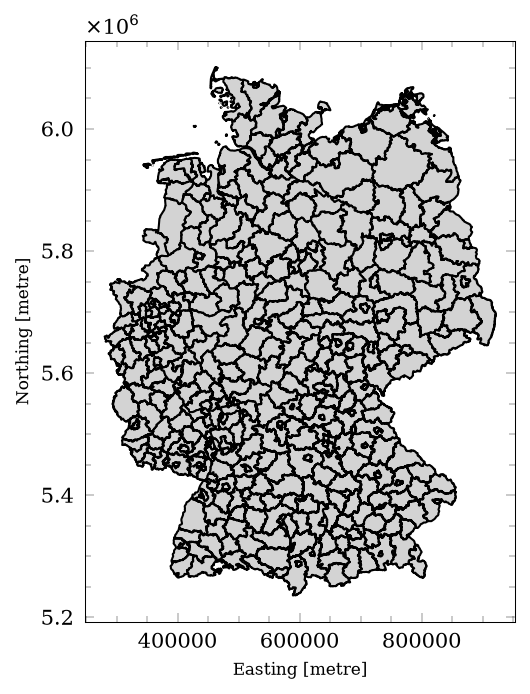

In [11]:
fig, ax = plt.subplots(figsize=(5, 5), dpi=150)
gdf.plot(ax=ax, color='lightgray', edgecolor='black')

# Class/Function Definitions

In [12]:
N_VARS = 3  # S, I, R

In [ ]:
class Parameters: # stores the constants and the movement matrix used by the model
    def __init__(self, *, alpha: float, beta: float, gamma: float, quarantine_factor: float) -> None:
        self.alpha = alpha # recovery rate
        self.beta = beta # rate of infection of susceptible
        self.gamma = gamma # vaccination rate (turning S into R)
        self.n_cities = W.shape[0] # number of counties
        self.W =  np.array((1 - quarantine_factor) *  W) # quarantine_factor controls how much movement is reduced. This scales the original matrix W
        self.W_colsum = jnp.sum(self.W, axis=0) # calcualte sum of each column of W

In [ ]:
@jax.jit(static_argnames=("p",)) # decorator, asks jax to compile the function for faster execution. p is a static compilation argument
def f(t, y: jnp.ndarray, p: Parameters):
    # t: current simulation time
    # y: current state of the entire system
    # p: the model parameters

    S, I, R = y.reshape((N_VARS, -1)) # unpack the state vector - takes the vector y containing everyone in every county and splits it into three arrays: susceptible people (S), infected people (I) and recovered/vaccinated people (R). (N_VARS = 3). y contains all current population values for all counties. -1: tells Python: “Work out how many columns are needed automatically."
    # S: num of susceptible people
    # I: num of infected people
    # R: num of resistant people

    N = S + I + R # total population size
    recovery_rate = p.alpha * I
    infection_rate = p.beta * S * I / N
    vaccination_rate = p.gamma * S

    dS = -infection_rate - vaccination_rate + p.W @ S - p.W_colsum * S 
    dI = infection_rate - recovery_rate + p.W @ I - p.W_colsum * I
    dR = vaccination_rate + recovery_rate + p.W @ R - p.W_colsum * R

    return jnp.concat((dS, dI, dR)) # tells the numerical solver how every state variable is changing at the current time

In [ ]:
def make_initial_condition(*,
                           initial_county: int | None = None,
                           initial_vaccination_rate: float = 0.0,
                           random_seed: int | None = None) -> np.ndarray:
    rng = np.random.default_rng(random_seed)

    if initial_county is not None:
        initial_infected_county = county_to_index[initial_county]
    else:
        initial_infected_county = rng.choice(len(start_counties))

    S0 = df_population["population"].to_numpy().astype(float) # S0: initial number of susceptible people in each county (whole population)
    I0 = np.zeros_like(S0)
    I0[initial_infected_county] = 1.0
    R0 = initial_vaccination_rate * S0
    S0 -= I0 + R0
    return np.concatenate((S0, I0, R0))

In [ ]:
# R0 = 12-18 - how many people can be infected by one person
# contagious period ~ 8 days
p = Parameters(alpha=1/8, beta=15/8, gamma=1 - 0.2**(1/365), quarantine_factor=0.9)
term = ODETerm(f) # tells the solver which equations to integrate
solver = Tsit5() # selects a numerical integration method, the Tsitouras fifth-order Runge–Kutta method.

In [17]:
y0 = make_initial_condition()

In [ ]:
t0 = 0.0
t1 = 100.0 # end time for the integration
dt0 = 1.0 # the initial or fixed step size
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0)) # Specifies which time points or steps to save in the output (defaults to t1).

In [ ]:
solution = diffeqsolve(term, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat) # diff equation solver, not using a fixed step size currently

In [ ]:
ts = solution.ts # array of time points at which the model saves its results.
ys = solution.ys.reshape((-1, N_VARS, p.n_cities)) # type: ignore (ignore this comment)
# shape of ys: (101, 3, n) is n are the counties and 3 is S, I, R

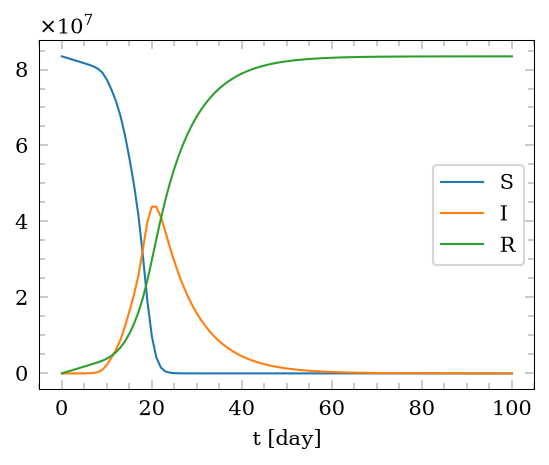

In [21]:
# plot S, I, R reduced over counties
plt.figure(figsize=(4, 3), dpi=150)
S_reduced = jnp.sum(ys[:, 0, :], axis=1)
I_reduced = jnp.sum(ys[:, 1, :], axis=1)
R_reduced = jnp.sum(ys[:, 2, :], axis=1)
plt.plot(ts, S_reduced, label="S")
plt.plot(ts, I_reduced, label="I")
plt.plot(ts, R_reduced, label="R")
plt.xlabel("t [day]")
plt.legend()

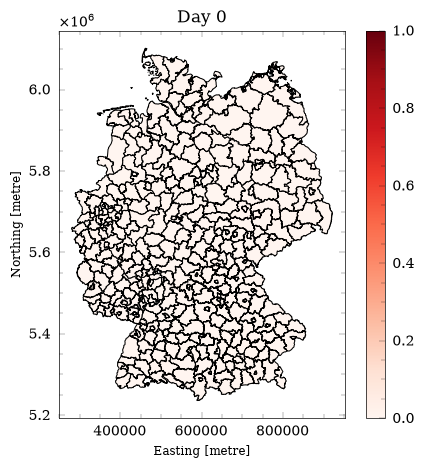

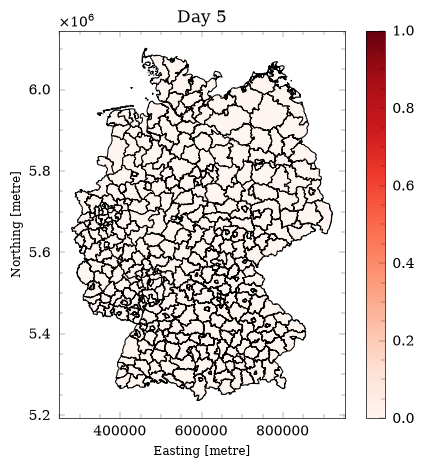

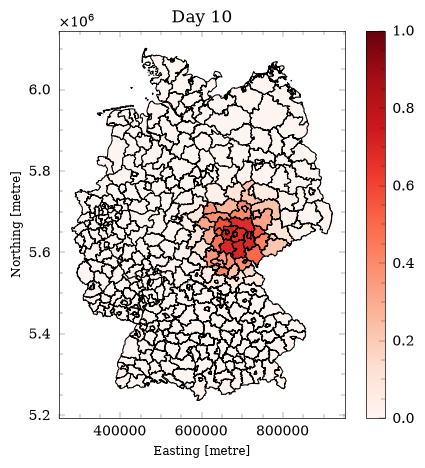

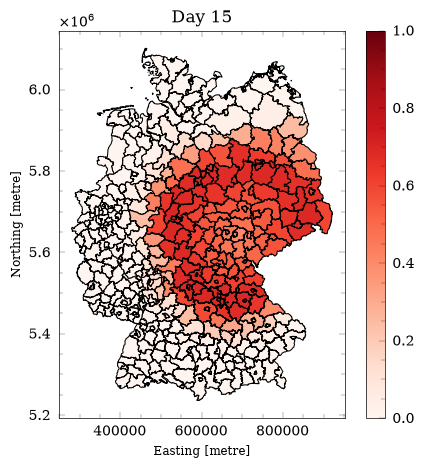

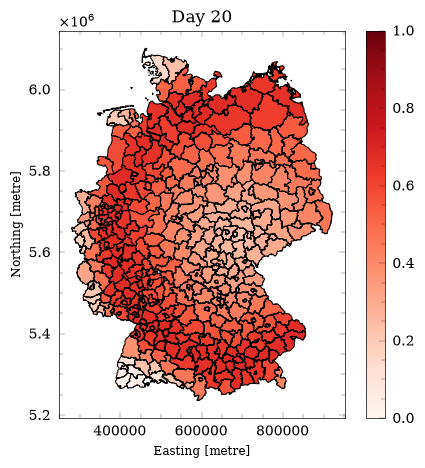

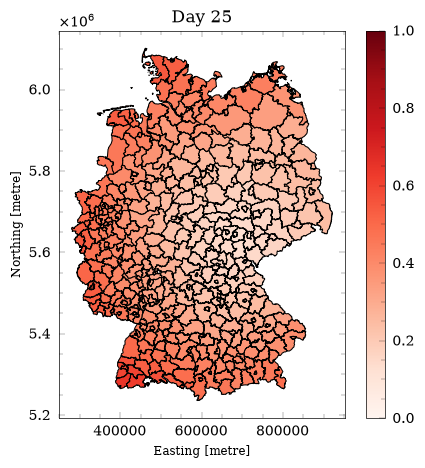

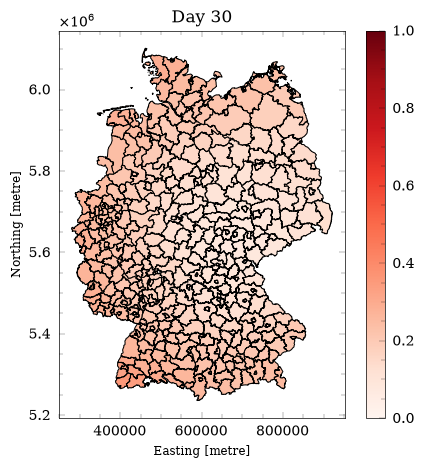

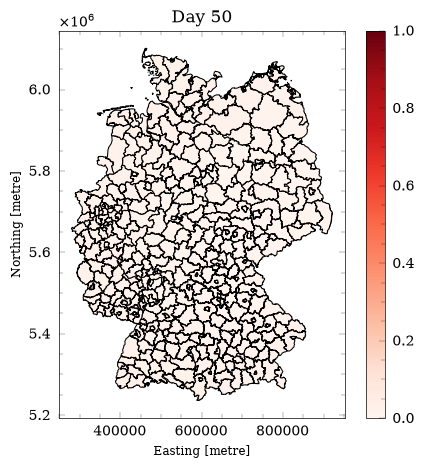

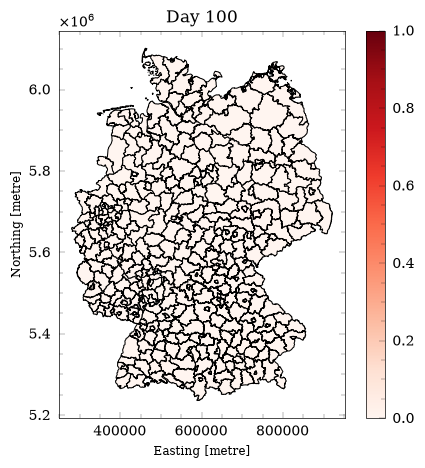

In [22]:
# plot map of infected individuals day 0, 50, 100, ..., 300
for day in [0, 5, 10, 15, 20, 25, 30, 50, 100]:
    plt.figure(figsize=(5,5))
    plt.title(f"Day {day}")
    S, I, R = ys[day, :, :]
    gdf['infected'] = I / (S + I + R)
    gdf.plot(column='infected', ax=plt.gca(), legend=True, cmap='Reds', edgecolor='black', linewidth=0.75, vmin=0, vmax=1)
    plt.show()